# Step 4: the Transformer, explained and checked

The real code lives in `ita/models/transformer.py`. This notebook **imports it** (there is only one copy),
shows each class, explains it, and checks it with small experiments.

| Part | Class | What it does |
|---|---|---|
| 1 | `MultiHeadAttention` | lets tokens read information from other tokens |
| 2 | `SinusoidalPositionalEncoding` | tells the model the order of the tokens |
| 3 | `SinusoidalTimestepEmbedding` | tells the decoder how noisy its input is |
| 4 | `FeedForward` | processes each token on its own |
| 5 | `EncoderLayer`, `DecoderLayer` | one block of the encoder / decoder |
| 6 | `Encoder`, `Decoder` | the full stacks, plus a small learning test |

Rule for the graded file: no `nn.Transformer`, `nn.MultiheadAttention` or `F.scaled_dot_product_attention`.

Run the cells in order with `Shift + Enter`.

In [1]:
%load_ext autoreload
%autoreload 2

import inspect
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import Markdown, display

from ita.models.transformer import (
    Decoder, DecoderLayer, Encoder, EncoderLayer, FeedForward, MultiHeadAttention,
    SinusoidalPositionalEncoding, SinusoidalTimestepEmbedding, _sinusoid,
)

def show(obj):
    """Print the source code of a class or function from transformer.py."""
    display(Markdown(f"```python\n{inspect.getsource(obj)}```"))

def n_params(module):
    return sum(p.numel() for p in module.parameters())

torch.manual_seed(0)
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())

torch 2.15.0+cu132 | GPU available: True


---
# Part 1: Multi-head attention

## 1.1 The idea, on a tiny example

Every token turns itself into three vectors:

- **Query (Q)**: what am I looking for?
- **Key (K)**: what do I contain?
- **Value (V)**: what do I hand over if someone picks me?

Each query is compared with every key using a dot product. A softmax turns the scores into weights
that sum to 1, and the output of each token is the weighted average of the values:

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

The next cell does this by hand for 3 tokens of size 4, with one head and no batch.

In [2]:
x = torch.randn(3, 4)                       # 3 tokens, each a vector of 4 numbers
W_q, W_k, W_v = (torch.randn(4, 4) for _ in range(3))

Q, K, V = x @ W_q, x @ W_k, x @ W_v         # (3, 4) each
scores = Q @ K.T / math.sqrt(4)             # (3, 3): row i = how well token i's query matches every key
weights = torch.softmax(scores, dim=-1)     # softmax over the keys (last dim)
out = weights @ V                           # (3, 4): weighted average of the values

print("scores:\n", scores.round(decimals=2))
print("\nweights (each row sums to 1):\n", weights.round(decimals=2))
print("\nrow sums:", weights.sum(-1))
print("output shape:", tuple(out.shape))

scores:
 tensor([[ 0.2900,  1.6500, -0.4300],
        [-2.3900,  1.2400, -0.0600],
        [-1.0100,  3.1700,  0.3100]])

weights (each row sums to 1):
 tensor([[0.1800, 0.7300, 0.0900],
        [0.0200, 0.7700, 0.2100],
        [0.0100, 0.9300, 0.0500]])

row sums: tensor([1.0000, 1.0000, 1.0000])
output shape: (3, 4)


**Read the weights matrix row by row.** Row 0 says how much token 0 takes from tokens 0, 1 and 2.
That is the whole mechanism. Everything below adds batches, several heads and masks around it.

## 1.2 Multi-head attention: the steps and shapes

Notation: B = batch, T_q = query tokens, T_k = key tokens, D = `d_model`, H = heads, d_head = D / H.

| # | Step | Shape after |
|---|---|---|
| 1 | `Q = W_q(q)`, `K = W_k(k)`, `V = W_v(v)` | (B, T, D) |
| 2 | split into heads: reshape to (B, T, H, d_head), then swap dims 1 and 2 | (B, H, T, d_head) |
| 3 | `scores = Q @ Kᵀ / √d_head` | (B, H, T_q, T_k) |
| 4 | masked scores set to `-inf` | (B, H, T_q, T_k) |
| 5 | softmax over the last dim, then dropout | (B, H, T_q, T_k) |
| 6 | `weights @ V` | (B, H, T_q, d_head) |
| 7 | merge heads: swap dims 1 and 2 back, reshape | (B, T_q, D) |
| 8 | output projection `W_o` | (B, T_q, D) |

Several heads let the model look for different things at the same time (one head can follow the gripper,
another the target object), for the same cost as one big head.

**Mask convention:** a boolean tensor where `True` means *this query may attend to this key*.
It arrives as (T_q, T_k) or (B, T_q, T_k) and is broadcast to the scores' shape (B, H, T_q, T_k).

The code in `transformer.py`:

In [3]:
show(MultiHeadAttention)

```python
class MultiHeadAttention(nn.Module):
    """softmax(Q K^T / sqrt(d_head)) V with n_heads heads, then an output projection."""

    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.last_attn: torch.Tensor | None = None  # weights of the last call, kept for inspection

    def _split_heads(self, x: torch.Tensor) -> torch.Tensor:
        """(B, T, D) -> (B, H, T, d_head)"""
        B, T, _ = x.shape
        return x.reshape(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor,
                mask: torch.Tensor | None = None) -> torch.Tensor:
        """q: (B, T_q, D), k/v: (B, T_k, D) -> (B, T_q, D)"""
        B, T_q, D = q.shape

        # Project, then split into heads.
        Q = self._split_heads(self.W_q(q))   # (B, H, T_q, d_head)
        K = self._split_heads(self.W_k(k))   # (B, H, T_k, d_head)
        V = self._split_heads(self.W_v(v))   # (B, H, T_k, d_head)

        # Similarity of every query with every key, scaled so the softmax stays smooth.
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_head)   # (B, H, T_q, T_k)

        # Mask: True = may attend. Add the missing dims so it broadcasts over batch and heads.
        if mask is not None:
            if mask.dim() == 2:          # (T_q, T_k)
                mask = mask[None, None]
            elif mask.dim() == 3:        # (B, T_q, T_k)
                mask = mask[:, None]
            scores = scores.masked_fill(~mask, float("-inf"))

        weights = torch.softmax(scores, dim=-1)   # over the keys
        self.last_attn = weights.detach()
        weights = self.dropout(weights)

        out = weights @ V                                  # (B, H, T_q, d_head)
        out = out.transpose(1, 2).reshape(B, T_q, D)       # merge heads -> (B, T_q, D)
        return self.W_o(out)
```

## 1.3 Check: shapes

Cross-attention, as in the decoder: 16 action tokens (queries) look at 7 observation tokens (keys and values).

In [4]:
B, T_q, T_k, D, H = 2, 16, 7, 64, 4
attn = MultiHeadAttention(D, H)

actions = torch.randn(B, T_q, D)       # queries: the 16 action tokens
obs = torch.randn(B, T_k, D)           # keys/values: the 7 observation tokens

y = attn(actions, obs, obs)
print("output:", tuple(y.shape), "   expected:", (B, T_q, D))
print("weights:", tuple(attn.last_attn.shape), " = (B, H, T_q, T_k)")
print("each row of weights sums to 1:", torch.allclose(attn.last_attn.sum(-1), torch.ones(B, H, T_q)))

output: (2, 16, 64)    expected: (2, 16, 64)
weights: (2, 4, 16, 7)  = (B, H, T_q, T_k)
each row of weights sums to 1: True


## 1.4 Check: the mask

A *causal* mask lets token i look only at tokens 0…i (lower triangle `True`).
After the softmax, everything above the diagonal must be exactly 0.

In [5]:
T = 5
causal = torch.tril(torch.ones(T, T, dtype=torch.bool))
print("mask (True = may attend):\n", causal.int())

attn = MultiHeadAttention(D, H).eval()
x = torch.randn(1, T, D)
attn(x, x, x, mask=causal)
print("\nweights of head 0:\n", attn.last_attn[0, 0].round(decimals=2))

mask (True = may attend):
 tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)

weights of head 0:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.4200, 0.5800, 0.0000, 0.0000, 0.0000],
        [0.2600, 0.3800, 0.3600, 0.0000, 0.0000],
        [0.1900, 0.2500, 0.2900, 0.2700, 0.0000],
        [0.2200, 0.1300, 0.2800, 0.2300, 0.1300]])


The same check as the official test: if nobody may attend to the last token,
changing that token must not change any other output.

In [6]:
S = 7
mask = torch.ones(S, S, dtype=torch.bool)
mask[:, -1] = False                     # nobody may look at the last token

x = torch.randn(B, S, D)
y1 = attn(x, x, x, mask=mask)
x2 = x.clone()
x2[:, -1] += 10.0                       # change the hidden token a lot
y2 = attn(x2, x2, x2, mask=mask)

print("other outputs unchanged:", torch.allclose(y1[:, :-1], y2[:, :-1], atol=1e-5))
print("last output changed:    ", not torch.allclose(y1[:, -1], y2[:, -1]))

other outputs unchanged: True
last output changed:     True


## 1.5 Check: attention has no sense of order

Shuffle the input tokens and the outputs come out shuffled the same way, with identical values.
Attention treats its input as a *set*. Part 2 is what tells the model that action 0 comes before action 15.

In [7]:
x = torch.randn(B, S, D)
perm = torch.randperm(S)
same = torch.allclose(attn(x, x, x)[:, perm], attn(x[:, perm], x[:, perm], x[:, perm]), atol=1e-5)
print("permutation:", perm.tolist())
print("shuffle-then-attend == attend-then-shuffle:", same)

permutation: [3, 1, 5, 6, 2, 4, 0]
shuffle-then-attend == attend-then-shuffle: True


## 1.6 Look at the attention weights

With random, untrained parameters the patterns mean nothing yet. Part 6 trains a tiny model and the
pattern becomes meaningful.

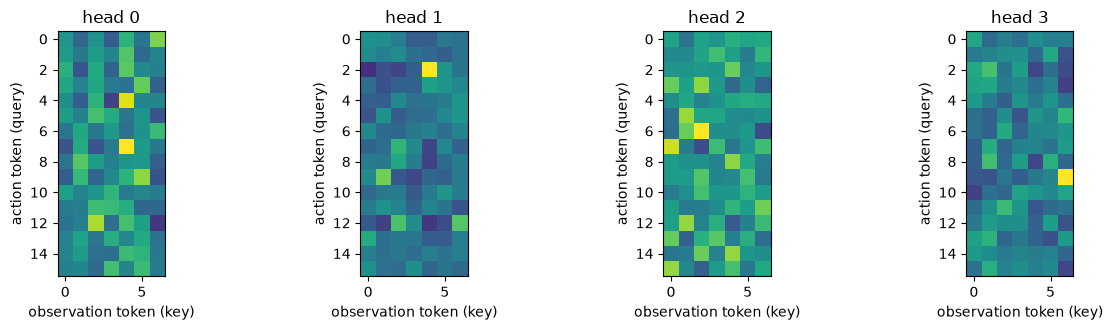

In [8]:
attn = MultiHeadAttention(D, H).eval()
attn(actions[:1], obs[:1], obs[:1])

fig, axes = plt.subplots(1, H, figsize=(3.2 * H, 3.4))
for h, ax in enumerate(axes):
    ax.imshow(attn.last_attn[0, h], cmap="viridis", vmin=0)
    ax.set_title(f"head {h}")
    ax.set_xlabel("observation token (key)")
    ax.set_ylabel("action token (query)")
fig.tight_layout()
plt.show()

## 1.7 Self-check

1. Why do we divide the scores by √d_head?
2. What would go wrong if masked scores were set to `0` instead of `-inf`?
3. Why must the softmax be over the last dimension?
4. In cross-attention, which tokens provide Q and which provide K and V? Why can T_q and T_k differ?

<details>
<summary>Answers</summary>

1. A dot product of two random d-dimensional vectors grows like √d. Large scores push the softmax towards a
   one-hot output whose gradients are almost zero, so training stalls. Dividing by √d_head keeps them near unit size.
2. `exp(0) = 1`, so the masked key would still get a positive weight and leak information. `exp(-inf) = 0`.
3. The last dimension indexes the keys. Each query spreads a total weight of 1 across the keys it looks at.
4. Q comes from the tokens asking (the 16 action tokens); K and V from the tokens being read (the observation
   tokens). The score matrix is T_q × T_k, so the counts never need to match; the output has T_q rows.
</details>

---
# Part 2: Positional encoding

## The idea

Part 1 showed that attention ignores order. But order matters: action 0 is executed now and action 15
in 1.5 seconds. The fix is to **add a different fixed vector to each position**, so the same token at
position 3 and at position 9 looks different.

The original Transformer uses sines and cosines of different frequencies:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/D}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/D}}\right)$$

Think of a clock: the first columns are the seconds hand (they change fast), the last columns are the
hours hand (they change slowly). Together they give every position a unique reading.

The table is **fixed**, not learned, so it is stored with `register_buffer` (it moves to the GPU with the
model but the optimizer never changes it).

In [9]:
show(_sinusoid)
show(SinusoidalPositionalEncoding)

```python
def _sinusoid(positions: torch.Tensor, dim: int) -> torch.Tensor:
    """Sin/cos features of 'Attention Is All You Need'. positions: (N,) -> (N, dim).

    Feature pair i uses the frequency 1 / 10000^(2i / dim): sin on even columns, cos on odd ones.
    """
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, dtype=torch.float32, device=positions.device) / half)
    args = positions.float()[:, None] * freqs[None, :]          # (N, half)
    out = torch.zeros(positions.shape[0], dim, device=positions.device)
    out[:, 0:2 * half:2] = torch.sin(args)
    out[:, 1:2 * half:2] = torch.cos(args)
    return out
```

```python
class SinusoidalPositionalEncoding(nn.Module):
    """Fixed sin/cos encoding from 'Attention Is All You Need'. Adds PE to x: (B, T, D) -> (B, T, D)."""

    def __init__(self, d_model: int, max_len: int = 512):
        super().__init__()
        pe = _sinusoid(torch.arange(max_len), d_model)               # (max_len, D)
        self.register_buffer("pe", pe[None], persistent=False)       # (1, max_len, D), not a parameter

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        T = x.shape[1]
        assert T <= self.pe.shape[1], f"sequence length {T} > max_len {self.pe.shape[1]}"
        return x + self.pe[:, :T]
```

## 2.1 Look at the table

Each row is a position, each column one feature. Left columns oscillate fast, right columns slowly.

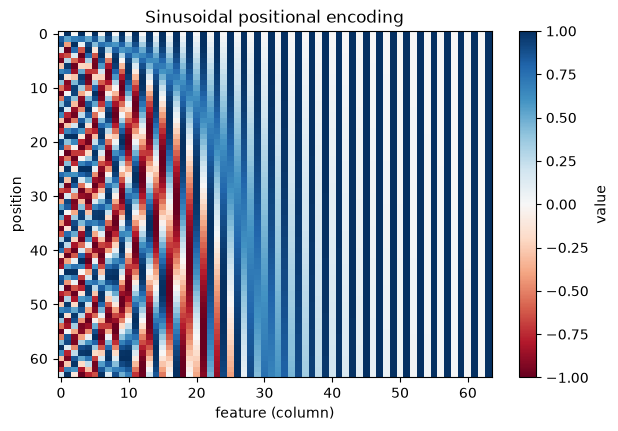

is it a trainable parameter? False


In [10]:
pe = SinusoidalPositionalEncoding(d_model=64, max_len=64)
table = pe.pe[0]                                    # (64 positions, 64 features)

plt.figure(figsize=(7, 4.5))
plt.imshow(table, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
plt.xlabel("feature (column)")
plt.ylabel("position")
plt.colorbar(label="value")
plt.title("Sinusoidal positional encoding")
plt.show()

print("is it a trainable parameter?", any(p is pe.pe for p in pe.parameters()))

## 2.2 Nearby positions look similar

Cosine similarity between position 8 and every other position: highest at 8, falling off with distance.

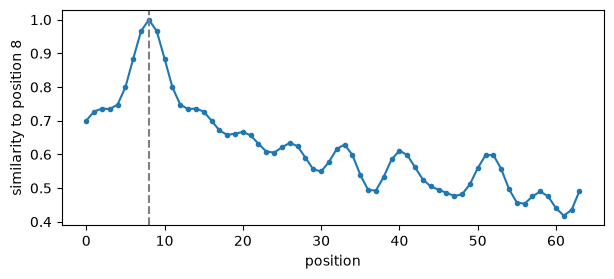

In [11]:
sim = torch.nn.functional.cosine_similarity(table[8:9], table, dim=-1)
plt.figure(figsize=(7, 2.8))
plt.plot(sim, marker=".")
plt.axvline(8, color="gray", linestyle="--")
plt.xlabel("position")
plt.ylabel("similarity to position 8")
plt.show()

## 2.3 Check: with positions added, order now matters

The same shuffle test as 1.5, but with the positional encoding added first. It must now be `False`.

In [12]:
attn = MultiHeadAttention(64, 4).eval()
x = torch.randn(2, 7, 64)
perm = torch.randperm(7)
xp, xpp = pe(x), pe(x[:, perm])                     # add positions AFTER shuffling the tokens
print("shuffle test still passes?", torch.allclose(attn(xp, xp, xp)[:, perm], attn(xpp, xpp, xpp), atol=1e-5))

shuffle test still passes? False


## 2.4 Self-check

1. Why not just add the number `pos` (0, 1, 2, …) as a feature?
2. Why use both sin and cos?
3. Why is the table a buffer and not a parameter?

<details>
<summary>Answers</summary>

1. The numbers would grow without bound (position 500 would dwarf every other feature), and the model would
   see positions it never met in training as totally new values. Sin/cos stay in [-1, 1].
2. A (sin, cos) pair at one frequency pins down the angle uniquely, and shifting the position by k is a rotation
   of that pair, which makes relative positions easy for attention to use.
3. It is a fixed formula. A buffer moves with the model (`.to(device)`) but is never updated by the optimizer.
</details>

---
# Part 3: Diffusion-step (timestep) embedding

## The idea

During training, noise of a random strength k (0 = almost clean, 99 = pure noise) is added to the
actions, and the decoder predicts that noise. To do this well it must **know k**: removing a little
noise and removing a lot of noise are different jobs.

k is a single integer, so we turn it into a D-dimensional vector:

1. the same sin/cos features as Part 2, with k in place of the position,
2. a small MLP (Linear → SiLU → Linear) that the model trains, so it can shape the signal as it needs.

In Step 8 this vector is added to every action token.

In [13]:
show(SinusoidalTimestepEmbedding)

```python
class SinusoidalTimestepEmbedding(nn.Module):
    """Embeds the diffusion step k (B,) integer -> (B, D). Same sin/cos formula, then an MLP."""

    def __init__(self, d_model: int):
        super().__init__()
        self.d_model = d_model
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.SiLU(),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        return self.mlp(_sinusoid(t, self.d_model))
```

input k: [0, 1, 50, 99] -> output shape (4, 256)
trainable parameters in the MLP: 525,568


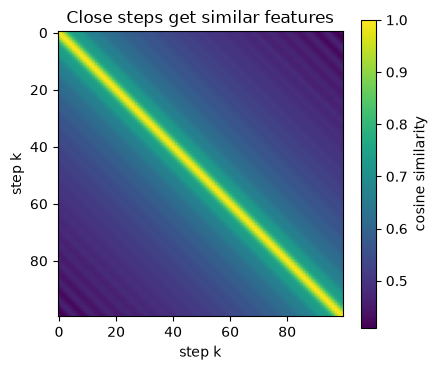

In [14]:
emb = SinusoidalTimestepEmbedding(d_model=256)
k = torch.tensor([0, 1, 50, 99])
e = emb(k)
print("input k:", k.tolist(), "-> output shape", tuple(e.shape))
print("trainable parameters in the MLP:", f"{n_params(emb):,}")

feats = _sinusoid(torch.arange(100), 256)           # the fixed features before the MLP
sim = torch.nn.functional.cosine_similarity(feats[:, None], feats[None], dim=-1)
plt.figure(figsize=(4.6, 4))
plt.imshow(sim, cmap="viridis")
plt.xlabel("step k")
plt.ylabel("step k")
plt.colorbar(label="cosine similarity")
plt.title("Close steps get similar features")
plt.show()

## 3.1 Self-check

1. What would happen if the decoder were not told k?
2. Why put an MLP after the sin/cos features?

<details>
<summary>Answers</summary>

1. It would have to guess the noise level from the noisy actions alone. At sampling time it runs 10 times with
   different noise levels, and without k it cannot tell how much to remove at each step.
2. The sin/cos features are fixed. The MLP lets training decide which aspects of k matter, and maps them to the
   same space as the action tokens they are added to.
</details>

---
# Part 4: Feed-forward network

## The idea

Attention **mixes** information between tokens. The feed-forward network then **processes each token on its
own**, with the same weights for every token: widen to `d_ff` (4 × D), apply a non-linearity (GELU), shrink back.
Most of a Transformer's parameters live here.

In [15]:
show(FeedForward)

```python
class FeedForward(nn.Module):
    """Linear(D, d_ff) -> GELU -> Dropout -> Linear(d_ff, D), applied to every token independently."""

    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)
```

In [16]:
ff = FeedForward(d_model=256, d_ff=1024).eval()
x = torch.randn(2, 16, 256)
y = ff(x)
print("shape:", tuple(x.shape), "->", tuple(y.shape))
print("parameters:", f"{n_params(ff):,}", "= 256*1024 + 1024 + 1024*256 + 256")

x2 = x.clone()
x2[:, 3] += 5.0                                      # change only token 3
changed = (ff(x2) - y).abs().amax(dim=(0, 2)) > 1e-6
print("which output tokens changed:", changed.nonzero().flatten().tolist(), " (only token 3)")

shape: (2, 16, 256) -> (2, 16, 256)
parameters: 525,568 = 256*1024 + 1024 + 1024*256 + 256
which output tokens changed: [3]  (only token 3)


## 4.1 Self-check

1. Why is the GELU needed between the two linear layers?
2. Why does changing token 3 change only output 3 here, but not in attention?

<details>
<summary>Answers</summary>

1. Two linear layers in a row are equivalent to a single linear layer. The non-linearity is what lets the block
   compute things a linear map cannot.
2. The FFN looks at one token at a time. Attention reads from all tokens, so every output can depend on token 3.
</details>

---
# Part 5: Encoder and decoder layers

## The idea

A layer combines the pieces with two tricks:

- **Residual connection** `x = x + f(x)`: each sub-block adds a correction instead of replacing `x`. Gradients
  flow straight through the `+`, so deep stacks still train.
- **Pre-LayerNorm** `x + f(LN(x))`: each token is normalised before entering the sub-block, which keeps training
  stable.

```
Encoder layer                         Decoder layer
x ─┬─ LN ─ Self-attn ─┐               x ─┬─ LN ─ Self-attn (actions ↔ actions) ─┐
   └──────────────────+                  └─────────────────────────────────────+
   ┬─ LN ─ FFN ───────┐                  ┬─ LN ─ Cross-attn (actions → memory) ─┐
   └──────────────────+                  └─────────────────────────────────────+
                                         ┬─ LN ─ FFN ───────────────────────────┐
                                         └─────────────────────────────────────+
```

In your policy the **encoder** fuses the 7 observation tokens (language, images, state). The **decoder**'s
action tokens talk to each other (self-attention), then read the encoder's output, called *memory*
(cross-attention).

In [17]:
show(EncoderLayer)
show(DecoderLayer)

```python
class EncoderLayer(nn.Module):
    """Pre-LN: x = x + SelfAttn(LN(x)); x = x + FFN(LN(x))."""

    def __init__(self, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, mask))
        x = x + self.drop(self.ff(self.norm2(x)))
        return x
```

```python
class DecoderLayer(nn.Module):
    """Pre-LN: x = x + SelfAttn(LN(x)); x = x + CrossAttn(LN(x), memory); x = x + FFN(LN(x))."""

    def __init__(self, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.self_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.cross_attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.norm3 = nn.LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor, memory: torch.Tensor,
                self_mask: torch.Tensor | None = None,
                cross_mask: torch.Tensor | None = None) -> torch.Tensor:
        """x: (B, T, D) action tokens, memory: (B, S, D) encoder output -> (B, T, D)"""
        h = self.norm1(x)
        x = x + self.drop(self.self_attn(h, h, h, self_mask))
        h = self.norm2(x)
        x = x + self.drop(self.cross_attn(h, memory, memory, cross_mask))
        x = x + self.drop(self.ff(self.norm3(x)))
        return x
```

In [18]:
D, H, FF = 64, 4, 128
enc_layer, dec_layer = EncoderLayer(D, H, FF).eval(), DecoderLayer(D, H, FF).eval()
obs, act = torch.randn(2, 7, D), torch.randn(2, 16, D)

memory = enc_layer(obs)
out = dec_layer(act, memory)
print("encoder layer:", tuple(obs.shape), "->", tuple(memory.shape))
print("decoder layer:", tuple(act.shape), "+ memory", tuple(memory.shape), "->", tuple(out.shape))
print("parameters: encoder layer", f"{n_params(enc_layer):,}", "| decoder layer", f"{n_params(dec_layer):,}",
      "(one more attention block)")

encoder layer: (2, 7, 64) -> (2, 7, 64)
decoder layer: (2, 16, 64) + memory (2, 7, 64) -> (2, 16, 64)
parameters: encoder layer 33,472 | decoder layer 50,240 (one more attention block)


## 5.1 Check: the decoder really reads the memory

Change the memory and the decoder output must change. Hide a memory token with `cross_mask` and changing that token must have no effect.

In [19]:
out1 = dec_layer(act, memory)
memory2 = memory.clone()
memory2[:, 0] += 5.0
print("output changes when memory changes:", not torch.allclose(out1, dec_layer(act, memory2)))

cross_mask = torch.ones(16, 7, dtype=torch.bool)
cross_mask[:, 0] = False                              # actions may not read memory token 0
same = torch.allclose(dec_layer(act, memory, cross_mask=cross_mask),
                      dec_layer(act, memory2, cross_mask=cross_mask), atol=1e-5)
print("hidden memory token has no effect:   ", same)

output changes when memory changes: True
hidden memory token has no effect:    True


## 5.2 Self-check

1. What does the residual `+` buy us when there are 8 layers?
2. In the decoder layer, which attention block mixes the 16 actions together, and which one brings in the camera
   and instruction information?

<details>
<summary>Answers</summary>

1. A direct path for the signal and the gradient. Each layer only has to learn a correction, and at
   initialisation the stack is close to the identity, so training starts from a sensible place.
2. Self-attention mixes the actions (so the 16 steps form a smooth trajectory). Cross-attention reads the memory,
   which holds the images, robot state and instruction.
</details>

---
# Part 6: The full encoder and decoder

## The idea

The encoder and decoder are stacks of the layers above, followed by a final LayerNorm. Here they are at the
size in `configs/default.yaml`: 4 + 4 layers, D = 256, 8 heads, d_ff = 1024.

In [20]:
show(Encoder)
show(Decoder)

```python
class Encoder(nn.Module):
    """Stack of n_layers EncoderLayer + final LayerNorm."""

    def __init__(self, n_layers: int, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.0):
        super().__init__()
        self.layers = nn.ModuleList(EncoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor, mask: torch.Tensor | None = None) -> torch.Tensor:
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)
```

```python
class Decoder(nn.Module):
    """Stack of n_layers DecoderLayer + final LayerNorm."""

    def __init__(self, n_layers: int, d_model: int, n_heads: int, d_ff: int, dropout: float = 0.0):
        super().__init__()
        self.layers = nn.ModuleList(DecoderLayer(d_model, n_heads, d_ff, dropout) for _ in range(n_layers))
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x: torch.Tensor, memory: torch.Tensor,
                self_mask: torch.Tensor | None = None,
                cross_mask: torch.Tensor | None = None) -> torch.Tensor:
        for layer in self.layers:
            x = layer(x, memory, self_mask, cross_mask)
        return self.norm(x)
```

In [21]:
enc = Encoder(n_layers=4, d_model=256, n_heads=8, d_ff=1024)
dec = Decoder(n_layers=4, d_model=256, n_heads=8, d_ff=1024)
print(f"encoder: {n_params(enc):>10,} parameters")
print(f"decoder: {n_params(dec):>10,} parameters")
print(f"total:   {n_params(enc) + n_params(dec):>10,}")

obs, act = torch.randn(2, 7, 256), torch.randn(2, 16, 256)
out = dec(act, enc(obs))
print("\nobservation tokens", tuple(obs.shape), "+ action tokens", tuple(act.shape), "->", tuple(out.shape))

encoder:  3,159,552 parameters
decoder:  4,214,272 parameters
total:    7,373,824

observation tokens (2, 7, 256) + action tokens (2, 16, 256) -> (2, 16, 256)


## 6.1 Check: every parameter receives a gradient

If a block were accidentally skipped in `forward`, its weights would get no gradient and never learn.

In [22]:
loss = dec(act, enc(obs)).pow(2).mean()
loss.backward()
missing = [n for n, p in list(enc.named_parameters()) + list(dec.named_parameters()) if p.grad is None]
print("parameters without a gradient:", missing if missing else "none")

parameters without a gradient: none


## 6.2 Learning test: can it route information?

A small sanity task before the real data. Each of 7 memory tokens is `[content | position]`: 32 random
numbers followed by its 32-number positional encoding. The decoder gets 7 queries `[0 | position]` that know
**only their position**. The target for query j is the content of memory token j.

To solve it, query j must match its position against the memory's positions through cross-attention and
copy that token's content. If the loss drops to about 0 and the cross-attention map becomes diagonal,
attention, positions, residuals and the stacks all work together.

(Content and position are kept in separate halves on purpose. If random content is added on top of the
position, the content drowns the position signal and no model can find the right token reliably.)

loss: start 1.352 -> end 0.0021
average attention on the correct memory token: 0.99


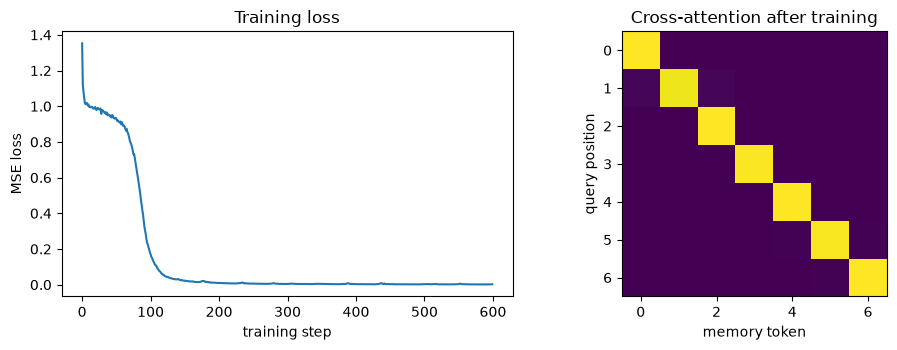

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
D, S, half, batch = 64, 7, 32, 256
pe = SinusoidalPositionalEncoding(half).to(device)
enc = Encoder(2, D, 4, 128).to(device)
dec = Decoder(2, D, 4, 128).to(device)
head = nn.Linear(D, half).to(device)
params = list(enc.parameters()) + list(dec.parameters()) + list(head.parameters())
opt = torch.optim.AdamW(params, lr=1e-3)
pos = pe(torch.zeros(batch, S, half, device=device))             # (batch, 7, 32) positions only

losses = []
for step in range(600):
    content = torch.randn(batch, S, half, device=device)        # what has to be copied
    memory = enc(torch.cat([content, pos], dim=-1))             # [content | position]
    queries = torch.cat([torch.zeros_like(content), pos], dim=-1)   # [   0    | position]
    loss = (head(dec(queries, memory)) - content).pow(2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

w_diag = dec.layers[-1].cross_attn.last_attn[0].mean(0).diagonal().mean().item()
print(f"loss: start {losses[0]:.3f} -> end {losses[-1]:.4f}")
print(f"average attention on the correct memory token: {w_diag:.2f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(losses)
axes[0].set_xlabel("training step")
axes[0].set_ylabel("MSE loss")
axes[0].set_title("Training loss")
w = dec.layers[-1].cross_attn.last_attn[0].mean(0).cpu()       # average over heads
axes[1].imshow(w, cmap="viridis")
axes[1].set_xlabel("memory token")
axes[1].set_ylabel("query position")
axes[1].set_title("Cross-attention after training")
fig.tight_layout()
plt.show()

## 6.3 Summary

| Check | Result |
|---|---|
| Attention shapes, mask, order-blindness | sections 1.3 – 1.5 |
| Positional encoding makes order matter | section 2.3 |
| Timestep embedding shape | Part 3 |
| FFN works per token | Part 4 |
| Decoder reads the memory, cross-mask works | section 5.1 |
| All parameters get gradients | section 6.1 |
| The stack can learn to route information | section 6.2 |

The official tests check the same file:

```bash
pytest tests/test_transformer.py -v      # 7 passed
```

**Next: Step 5, the diffusion scheduler.**